<a href="https://colab.research.google.com/github/Luuuuuig/Bachelor-End-Project/blob/main/Focal_Case_Selection_2026-10-07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Selecting the focal case
**7 October numerical scenario, reviewed 9 October 2026. Yijie's provisional assessment; supervisor review pending.**

This notebook supports a provisional choice of the purchasing activity that the AI-supported improvement will focus on. It answers SQ4 of the submitted [Plan of Work](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/proposal/Plan_of_Work_Final_2026-09-22.pdf), using the workflow evidence of SQ1 and the workload evidence of SQ3 from the [analysis notebook](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/Arno_Analysis_2026_10_02.ipynb). It follows the selection rule of the [methodology, §5.3](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Phase_1_Current_Methodology.md#53-formal-two-stage-selection-rule): veto gates first, weighted scores second, then a sensitivity check.

Everything the selection uses is in this notebook: the findings it starts from, the gate verdicts, the weights, the scores and the evidence behind each of them. It loads no files.

## Summary

- **The analysis** found three areas that carry the most recorded time: PO preparation and completion (19.8% of the 560 in-scope minutes), order and confirmation checking (17.5%) and request intake (16.8%). Six candidate areas were assessed (part 1).
- **Stage A (veto gates):** PO supplier communication leaves the comparison (gate 6: ordinary automation is enough), and standard / review / manual leaves as a stand-alone candidate (gate 5: too large for the BEP; it stays the design frame of the focal case). Maximalisatie and request intake continue only in a narrower form; order and confirmation checking and article data pass provisionally (part 3).
- **Weights:** Yijie's individual swing weights, recorded before any scoring; the weighting procedure and final set await review with Zhongxin (part 5).
- **Stage B (weighted scores):** order and confirmation checking **76.2 of 100**, ahead of article data (56.8), maximalisatie (51.9) and request intake (50.8). It scores highest or joint highest on every criterion (parts 6–7).
- **Sensitivity:** order and confirmation checking stays first in every check that changes one thing at a time. Six one-point changes together, within the recorded ranges, would put article data ahead (part 8).
- **Provisional focal case: order and confirmation checking** (called purchase-price control until 7 October), under four conditions: the Exact test-account and reference checks, Arno's acceptance, review of the boundary, criteria, scores and weights with Zhongxin, and Johan's confirmation of the business value (part 9).

## How to read this notebook

| Part | Question |
|---|---|
| 1. What the analysis found | Which candidate areas are there, and what does the observed work say about them? |
| 2. How the choice is made | Why veto gates first and weighted scores second, and what supports this? |
| 3. Stage A: veto gates | Which candidates may be compared, in which form? |
| 4. Criteria and scoring anchors | What does each criterion measure, and what do the scores 1, 3 and 5 mean? |
| 5. Weights | How much does each criterion count, and why? |
| 6. Scores | Which score does each candidate get, on what evidence? |
| 7. Totals | Which candidate comes first? |
| 8. Sensitivity | Does the result hold if the judgements are a little different? |
| 9. The focal case | What is chosen, and under which conditions? |

**Status.** This is a provisional assessment by one person. The gate verdicts and scores were drafted from the [evidence matrix](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Candidate_Evidence_Matrix_2026-10-07.md) with AI assistance and reviewed by Yijie. Several rest on evidence that is expected but not yet seen, mainly in the Exact test account; each such verdict names the check that settles it, using the IDs of the [Stage A worksheet](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Stage_A_Test_Account_Check_2026-10-07.xlsx). The [8 October meeting](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/meetings/Academic_Supervisor_Meeting_Notes_2026-10-08.md#selecting-the-improvement-task) requested criterion definitions and rationale and agreed to review weights. It did not select a task or adopt an independent-elicitation procedure. If the existing independent-weight proposal is used, collect that set before showing these scores. The numerical scenario below is retained from 7 October; the wider boundary has not been used to produce new scores.

As in the course notebooks, the libraries are loaded once and the plot defaults are set here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots, as in the course notebooks
sns.set()                                  # set Seaborn defaults
plt.rcParams["figure.figsize"] = 10, 5     # default hor./vert. size of plots, in inches

## 1. What the analysis found

The [analysis notebook](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/Arno_Analysis_2026_10_02.ipynb) describes five observation sessions of Arno, between 31 August and 23 September: 892 minutes of observation and 742 recorded activity minutes, after leaving out 9 minutes of lost focus. Of these, 182 minutes are former EXC work, which stays outside the improvement scope (decision of 1 October). The comparison uses the remaining **560 minutes**. Ordering is the largest purchasing stage, with 334 of the 560 minutes (59.6%).

**The candidate areas.** The six areas come from the candidate portfolio of the [methodology (§4)](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Phase_1_Current_Methodology.md#4-current-candidate-portfolio); article / supplier data was added during Analyze. Each area is a set of kinds of work from the [codebook](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/measurement/Kinds_Of_Work_Codebook.md) (K-codes). The figures below are copied from parts 6 and 9 of the analysis notebook; part 11 of that notebook lists what it hands over to this selection.

In [2]:
# Candidate areas with their recorded workload (analysis notebook, parts 6 and 9)
candidates = pd.DataFrame([
    ("Order and confirmation checking", "K04, K17, K18", 98, 19, 5,
     "Read price, quantity, delivery date and lines from quotations and confirmations, match them to the PO, flag differences"),
    ("Request intake & validation", "K08–K11", 94, 11, 5,
     "Find earlier POs and drawings, flag missing information"),
    ("Standard / review / manual", "Process level (closest: K02 PO preparation)", 111, 34, 5,
     "Route standard cases straight through, send exceptions to the buyer"),
    ("Maximalisatie", "K03", 43, 16, 5,
     "Show open POs and demand that could be combined"),
    ("Article / supplier data", "K12", 39, 5, 4,
     "Extract item and supplier fields from supplier documents"),
    ("PO supplier communication", "K05", 36, 23, 4,
     "Send the generated PO with a standard message"),
], columns=["candidate", "kinds_of_work", "minutes", "case_days", "days_seen", "possible_support"])

# Share of the 560 in-scope minutes
candidates["share_pct"] = candidates["minutes"] / 560 * 100
candidates.sort_values("minutes", ascending=False).round(1)

,candidate,kinds_of_work,minutes,case_days,days_seen,possible_support,share_pct
2,Standard / review / manual,Process level (closest: K02 PO preparation),111,34,5,"Route standard cases straight through, send ex...",19.8
0,Order and confirmation checking,"K04, K17, K18",98,19,5,"Read price, quantity, delivery date and lines ...",17.5
1,Request intake & validation,K08–K11,94,11,5,"Find earlier POs and drawings, flag missing in...",16.8
3,Maximalisatie,K03,43,16,5,Show open POs and demand that could be combined,7.7
4,Article / supplier data,K12,39,5,4,Extract item and supplier fields from supplier...,7.0
5,PO supplier communication,K05,36,23,4,Send the generated PO with a standard message,6.4


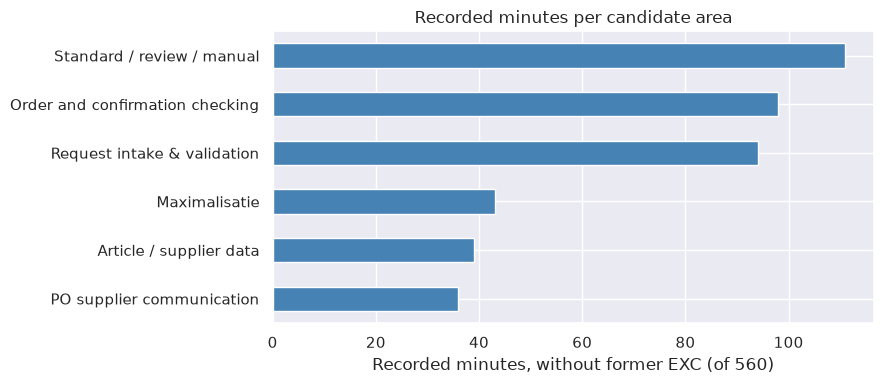

In [3]:
ax = candidates.sort_values("minutes").plot(kind="barh", x="candidate", y="minutes", legend=False, color="steelblue", figsize=(9, 4))
ax.set_xlabel("Recorded minutes, without former EXC (of 560)")
ax.set_ylabel("")
ax.set_title("Recorded minutes per candidate area")
plt.tight_layout()
plt.show()

**Reading.**

- **Three areas carry the most time:** PO preparation and completion (111 minutes, 19.8%), order and confirmation checking (98, 17.5%) and request intake (94, 16.8%). The other areas take 6–8% each. The areas overlap, because one record can have up to three kinds of work, so the minutes are not added up.
- **What the 98 minutes contain.** 28 minutes are in records whose note names a price check or a price difference, 6 in a price check that could not be completed, 4 name a missing delivery date and 4 attach a confirmation. The notes of the other 56 minutes do not say what was checked; Yijie, who observed the sessions, clarified on 7 October that these were regular price and delivery-date checks. So **94 of the 98 minutes are checks of price and/or delivery date**. Attaching the confirmation is a fixed step that was not always written down, so its 4 minutes are not counted as checking. Part 8 still tests the 28 price-named minutes as a lower bound.
- **Reported causes of the order checks** (analysis notebook, part 10; Yijie's account of earlier conversations, still to be confirmed by Arno): orders and supplier documents are compared by hand (PC-1), Exact does not compare a confirmation with the PO (PC-6), prices in Exact are outdated because the buyers lack time (PC-5), and supplier prices change (PC-10).
- **Limits.** Five partial sessions of one buyer; the kinds of work were assigned by one coder, and the 9 October source-to-label desk review records the remaining coding-owner questions. Recorded minutes are observed parts of tasks, not complete task times or savings. Broad checking includes 11 K18 minutes whose eligibility for the narrower quotation/confirmation intervention is unresolved (part 6).

The observations show where the time goes. They cannot show whether the data for a prototype exist, whether a correct answer can be checked, whether the buyer would accept the support, or whether AI is needed. The rest of the selection asks those questions.

## 2. How the choice is made, and why

The selection follows **multi-criteria decision analysis (MCDA)**: list the options, define the criteria, score each option on each criterion, weight the criteria, combine the scores, and test how sensitive the result is (Department for Communities and Local Government [DCLG], 2009; Belton & Stewart, 2002). The methodology adds one step before the scoring: veto gates.

| Step | What it does | Why |
|---|---|---|
| **Stage A: veto gates** | Six requirements, each Pass, Provisional pass, Redesign or Reject (part 3) | A weighted sum is *compensatory*: a high score on one criterion can make up for a low score on another (Belton & Stewart, 2002). That suits preferences such as workload, but not requirements such as permission to use the data or a correct answer to test against. Those are checked first, and a failed gate cannot be made up by a high score. |
| **Stage B: weighted scores** | Seven criteria, each scored 1–5 against written anchors, combined with weights into a total of 0–100 (parts 4–7) | The weighted sum (the additive model of MCDA) makes every step visible: each score has its evidence, and each weight its reason (DCLG, 2009). |
| **Weights by swing weighting** | Each criterion's weight reflects how much it matters to move a candidate from score 1 to score 5 (part 5) | A weight should reflect the difference between the worst and the best score on a criterion, not how important the criterion sounds in general (DCLG, 2009; Belton & Stewart, 2002). |
| **Sensitivity check** | The totals are recalculated with other weights and scores (part 8) | Weights and scores are judgements. A ranking is only useful if it does not flip with small, plausible changes to them (Triantaphyllou & Sánchez, 1997). |

**Who decides what** (methodology §5.3): Yijie builds the matrix, documents the evidence and calculates the scores. Yijie and the academic supervisor agree the criteria, anchors and weights. The company supervisor validates the operational evidence: workload, business value, data access and risk controls. Buyers' explanations, such as Dennis's on outdated prices, are evidence he can confirm.

The sources are listed at the end and in the [literature register](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/literature/README.md); read the relevant chapters before citing them in the thesis.

Zhongxin described the weighted comparison as support for the choice on 8 October and advised concentrating the more substantial evaluation on the developed solution. The seven criteria and cut-offs are project judgements informed by the cited methods, not requirements established by those sources. Achieved savings after implementation cannot be used to choose which solution to build.

## 3. Stage A: veto gates

| Gate | Question | Why it is a veto | Basis |
|---|---|---|---|
| 1 | Are the data and tools permitted for this research use? | Without permission, the data cannot be used at all. | Company permission (Johan) |
| 2 | Are the accessible data representative enough for a prototype and a test? | A prototype built on unrepresentative data says nothing about the real task. | Methodology §5.2 |
| 3 | Can a reproducible reference answer and manual baseline be created? | Without a correct answer to compare with, the support cannot be evaluated, so SQ5 cannot be answered. | Evaluation in DSRM (Peffers et al., 2007); methodology §6 |
| 4 | Are critical errors detectable or reversible, with human review, an audit trail and a fallback? | Includes acceptance of the specific function: on 8 October Yijie reported buyer opposition to automatic PO creation and email sending, not a verdict on a bounded review aid. | Levels of automation (Parasuraman et al., 2000); 8 October meeting |
| 5 | Do the prototype and the evaluation fit the BEP's time, access and participants? | A case that cannot be finished within the BEP cannot answer the research question. | Plan of Work |
| 6 | Does AI add value beyond a simpler rule? | The company expects an AI contribution; if a fixed rule is enough, the task is a quick win, not the AI artifact. | Project charter; task–technology fit (Goodhue & Thompson, 1995) |

**Verdicts.** *Pass*: shown by the evidence. *Provisional pass*: expected, with the check that confirms it. *Redesign*: passes only in a narrower form, described in the reason. *Reject*: the candidate leaves the comparison.

The next six cells record the verdict for each candidate and gate, with the reason and, for a provisional verdict, the check that settles it.

A provisional pass is permission to explore the scenario, not evidence that the gate is closed. Existing pass labels on low-autonomy alternatives describe the proposed control arrangement; they do not establish buyer endorsement. If an alternative is pursued, verify its function-specific acceptance. An unflagged result must not be treated as automatically correct or released without the agreed human control.

In [4]:
# Stage A for Order and confirmation checking: gate, verdict, reason, check that settles it
gate_rows = []

candidate = 'Order and confirmation checking'
gate_rows += [
    (candidate, 1, 'Pass',
     "Johan's permission covers using the test-account data and processing its documents "
     'with an external AI service (checks G1–G2, confirmed by Yijie on 7 October). What '
     'must be anonymised in the thesis (G3) sets how results are reported, not whether the'
     ' data may be used.',
     ''),
    (candidate, 2, 'Provisional pass',
     'PO lines are standard Exact records and the observations provide examples. Whether '
     'matching confirmations/quotations exist and represent the target work remains '
     'unverified. Inspect their period and current-practice differences. If unsuitable, '
     'demonstrate a permitted representative alternative before final selection; the '
     'provisional scores do not close this gate.',
     'PC1–PC3, G4, G5'),
    (candidate, 3, 'Provisional pass',
     'The proposed reference is the approved price per line. The buyer must verify its '
     'correctness, version and applicability to the item, quantity and order date. '
     'Availability and traceability are not yet established. Demonstrate a trustworthy '
     'source before final selection. Constructing test workloads does not supply their '
     'correct answers. For delivery date, quantity and line presence, a versioned PO '
     'is a comparison input, not automatic proof of the accepted business answer. '
     'Validate document fields, discrepancy labels and accepted actions separately.',
     'PC4, PC6'),
    (candidate, 4, 'Provisional pass',
     'The function only flags differences; the buyer judges each one and nothing changes '
     "in Exact without the buyer. On 8 October Yijie reported objection to automatic "
     "PO creation and email sending. This does not establish acceptance or rejection "
     "of flagging. Arno's acceptance of the specific support remains open.",
     'Arno session, part D (rows 5–6)'),
    (candidate, 5, 'Provisional pass',
     'A prototype on exported PO lines and supplier documents could fit the BEP without '
     'Exact integration. This depends on successful exports, matched documents and buyer '
     'time for manual comparison; these checks remain open.',
     'G6, PC1, PC7'),
    (candidate, 6, 'Provisional pass',
     'Notes describe paper, PDF, website and email prices with differing item '
     'descriptions. This may justify AI-assisted reading/matching. Inspect actual samples '
     'and compare the proposed role with structured data, OCR, search and deterministic '
     'rules. The Tater et al. precedent still requires full-text review and does not '
     'establish added value here.',
     'PC2'),
]

In [5]:
# Stage A for Article / supplier data: gate, verdict, reason, check that settles it
candidate = 'Article / supplier data'
gate_rows += [
    (candidate, 1, 'Pass',
     "Johan's permission covers using the test-account data and processing its documents "
     'with an external AI service (checks G1–G2, confirmed by Yijie on 7 October).',
     ''),
    (candidate, 2, 'Provisional pass',
     'Article records exist in Exact; whether the supplier documents used to create them '
     'are linked is not yet known.',
     'AR2'),
    (candidate, 3, 'Provisional pass',
     'Existing article records are candidate references for extracted fields, subject to '
     'checking against source documents and buyer-approved values. Do not assume '
     'historical master data are correct.',
     'AR1'),
    (candidate, 4, 'Pass',
     'The buyer checks the fields before creating the article.',
     ''),
    (candidate, 5, 'Provisional pass',
     'A bounded prototype could use exported article records and supplier documents if '
     'exports and matching inputs are available; that availability remains to be checked.',
     'G6, AR2'),
    (candidate, 6, 'Provisional pass',
     'Different supplier-document layouts may justify AI-assisted field extraction. '
     'Inspect actual samples and compare with simpler extraction/rules; the cited '
     'benchmark is a research lead, not demonstrated performance in this setting.',
     ''),
]

In [6]:
# Stage A for Maximalisatie: gate, verdict, reason, check that settles it
candidate = 'Maximalisatie'
gate_rows += [
    (candidate, 1, 'Provisional pass',
     "Johan's permission covers using the test-account data and processing its documents "
     'with an external AI service (checks G1–G2, confirmed by Yijie on 7 October). Whether'
     ' demand data in Orbis are also needed and permitted is not yet known.',
     'MX4'),
    (candidate, 2, 'Redesign',
     'Full decision support needs past stock, advice and lead-time states, which a test '
     'copy is unlikely to hold. Narrowed output: when a PO is created, a list of the open '
     'POs and pending demand for the same supplier; the buyer decides whether to combine '
     'or hold.',
     'MX1, MX2'),
    (candidate, 3, 'Redesign',
     'No validated reference for a good hold-or-order decision has been demonstrated, so '
     'the proposed redesign excludes that decision. Lines later added to a PO are '
     'candidate examples for related-demand retrieval; the buyer must check relevance and '
     'omissions before they serve as reference answers.',
     'MX3'),
    (candidate, 4, 'Pass',
     'A suggestion only; the buyer decides.',
     ''),
    (candidate, 5, 'Provisional pass',
     'The narrowed version fits the BEP if open POs and demand can be exported; the full '
     'version depends on Exact and Orbis data.',
     'G6, MX4'),
    (candidate, 6, 'Provisional pass',
     'Listing same-supplier open POs and demand is close to a rule. Matching free-text '
     'demand may justify AI only if actual examples show useful support beyond simple '
     'search/rules.',
     ''),
]

In [7]:
# Stage A for Request intake & validation: gate, verdict, reason, check that settles it
candidate = 'Request intake & validation'
gate_rows += [
    (candidate, 1, 'Provisional pass',
     "Johan's permission covers using the test-account data and processing its documents "
     'with an external AI service (checks G1–G2, confirmed by Yijie on 7 October). Access '
     'to the drawing archive is not yet known.',
     'RI2'),
    (candidate, 2, 'Redesign',
     'Requests arrive by email, at the desk or by phone and are probably not stored in '
     'Exact. Narrowed output: for the item being ordered, the old POs and the drawings '
     'found in Exact or the drawing archive, for the buyer to use.',
     'RI1, RI2'),
    (candidate, 3, 'Redesign',
     'No validated list of required drawings or complete-request definition is available '
     'for completeness assessment, so the proposed redesign excludes it. Previously used '
     'POs/drawings are candidate retrieval references; the buyer must verify their '
     'relevance, revision and completeness before evaluation.',
     'RI3'),
    (candidate, 4, 'Pass',
     'Retrieval and flags only; the buyer decides.',
     ''),
    (candidate, 5, 'Provisional pass',
     'Depends on access to where drawings are kept.',
     'RI2'),
    (candidate, 6, 'Provisional pass',
     'Free-text item descriptions may justify AI-assisted retrieval of POs/drawings. '
     'Inspect actual examples and establish whether it adds useful support beyond ordinary'
     ' search and rules.',
     ''),
]

In [8]:
# Stage A for Standard / review / manual: gate, verdict, reason, check that settles it
candidate = 'Standard / review / manual'
gate_rows += [
    (candidate, 1, 'Pass',
     "Johan's permission covers using the test-account data and processing its documents "
     'with an external AI service (checks G1–G2, confirmed by Yijie on 7 October).',
     ''),
    (candidate, 2, 'Provisional pass',
     'PO records exist, but nothing marks a case as standard, review or manual.',
     'SR1'),
    (candidate, 3, 'Redesign',
     'No reference standard exists without the buyer labelling past cases.',
     'SR1'),
    (candidate, 4, 'Redesign',
     "The automatic creation-and-sending arrangement conflicts with the buyers' objection "
     'reported on 8 October. A bounded review aid requires its own acceptance check.',
     'Arno session, part D'),
    (candidate, 5, 'Reject',
     'As a stand-alone candidate, an end-to-end routing redesign with Exact integration '
     'does not fit the BEP. It stays the design frame for the chosen task: cases without a'
     ' flag are standard, flagged cases go to review.',
     ''),
    (candidate, 6, 'Provisional pass',
     'Routing can largely be rules; AI fits only specific steps.',
     ''),
]

In [9]:
# Stage A for PO supplier communication: gate, verdict, reason, check that settles it
candidate = 'PO supplier communication'
gate_rows += [
    (candidate, 1, 'Pass',
     "Johan's permission covers using the test-account data and processing its documents "
     'with an external AI service (checks G1–G2, confirmed by Yijie on 7 October).',
     ''),
    (candidate, 2, 'Provisional pass',
     'Sent PO emails are probably retrievable.',
     'CM1'),
    (candidate, 3, 'Provisional pass',
     'A buyer-verified recipient, attachment and message could provide a reference. A '
     'historically sent email alone does not establish correctness; validate reference '
     'examples if this supporting opportunity is pursued.',
     ''),
    (candidate, 4, 'Provisional pass',
     'On 8 October Yijie reported opposition to automatic PO creation and email sending '
     'as one arrangement. Acceptance of a separate draft or send function still needs '
     'its own check; do not assume consent to automatic sending.',
     'Arno session, part D (row 11)'),
    (candidate, 5, 'Pass',
     'Small and buildable within the BEP.',
     ''),
    (candidate, 6, 'Reject',
     'Forwarding a generated PO with a standard message is a deterministic step; ordinary '
     'automation is enough. Kept as a quick-win recommendation.',
     ''),
]

In [10]:
# Verdict per candidate and gate
gates = pd.DataFrame(gate_rows, columns=["candidate", "gate", "verdict", "reason", "check"])
gate_table = gates.pivot(index="candidate", columns="gate", values="verdict")
gate_table.columns = [f"Gate {g}" for g in gate_table.columns]
gate_table

,Gate 1,Gate 2,Gate 3,Gate 4,Gate 5,Gate 6
candidate,,,,,,
Article / supplier data,Pass,Provisional pass,Provisional pass,Pass,Provisional pass,Provisional pass
Maximalisatie,Provisional pass,Redesign,Redesign,Pass,Provisional pass,Provisional pass
Order and confirmation checking,Pass,Provisional pass,Provisional pass,Provisional pass,Provisional pass,Provisional pass
PO supplier communication,Pass,Provisional pass,Provisional pass,Provisional pass,Pass,Reject
Request intake & validation,Provisional pass,Redesign,Redesign,Pass,Provisional pass,Provisional pass
Standard / review / manual,Pass,Provisional pass,Redesign,Redesign,Reject,Provisional pass


In [11]:
# Stage A result: the most severe verdict of each candidate
severity = {"Pass": 0, "Provisional pass": 1, "Redesign": 2, "Reject": 3}
labels = {0: "Pass", 1: "Provisional pass", 2: "Redesign", 3: "Reject"}
gates["severity"] = gates["verdict"].map(severity)
stage_a = gates.groupby("candidate")["severity"].max().map(labels).to_frame("stage_a_result")
stage_a["scored_in_stage_b"] = stage_a["stage_a_result"] != "Reject"
stage_a.sort_values("stage_a_result")

,stage_a_result,scored_in_stage_b
candidate,,
Article / supplier data,Provisional pass,True
Order and confirmation checking,Provisional pass,True
Maximalisatie,Redesign,True
Request intake & validation,Redesign,True
PO supplier communication,Reject,False
Standard / review / manual,Reject,False


In [12]:
# The reasons behind every Redesign and Reject
with pd.option_context("display.max_colwidth", 200):
    display(gates.loc[gates["verdict"].isin(["Redesign", "Reject"]), ["candidate", "gate", "verdict", "reason", "check"]])

,candidate,gate,verdict,reason,check
13,Maximalisatie,2,Redesign,"Full decision support needs past stock, advice and lead-time states, which a test copy is unlikely to hold. Narrowed output: when a PO is created, a list of the open POs and pending demand for the...","MX1, MX2"
14,Maximalisatie,3,Redesign,"No validated reference for a good hold-or-order decision has been demonstrated, so the proposed redesign excludes that decision. Lines later added to a PO are candidate examples for related-demand...",MX3
19,Request intake & validation,2,Redesign,"Requests arrive by email, at the desk or by phone and are probably not stored in Exact. Narrowed output: for the item being ordered, the old POs and the drawings found in Exact or the drawing arch...","RI1, RI2"
20,Request intake & validation,3,Redesign,"No validated list of required drawings or complete-request definition is available for completeness assessment, so the proposed redesign excludes it. Previously used POs/drawings are candidate ret...",RI3
26,Standard / review / manual,3,Redesign,No reference standard exists without the buyer labelling past cases.,SR1
27,Standard / review / manual,4,Redesign,The automatic creation-and-sending arrangement conflicts with the buyers' objection reported on 8 October. A bounded review aid requires its own acceptance check.,"Arno session, part D"
28,Standard / review / manual,5,Reject,"As a stand-alone candidate, an end-to-end routing redesign with Exact integration does not fit the BEP. It stays the design frame for the chosen task: cases without a flag are standard, flagged ca...",
35,PO supplier communication,6,Reject,Forwarding a generated PO with a standard message is a deterministic step; ordinary automation is enough. Kept as a quick-win recommendation.,


**Reading.**

- **Two candidates leave the comparison.** *PO supplier communication* fails gate 6: forwarding a generated PO with a standard message is a fixed step that ordinary automation can do, so it stays a quick-win recommendation. *Standard / review / manual* fails gate 5 as a stand-alone candidate: an end-to-end routing redesign with Exact integration does not fit the BEP. It stays the design frame for the chosen task, where cases without a flag follow the standard route and flagged cases go to the buyer.
- **Two candidates continue only in a narrower form.** Neither has a reference answer for its original task, so each is redefined by what it would produce, and part 6 scores that output only:

  | Candidate | Narrowed output | Reference answer for that output | Left out, and why |
  |---|---|---|---|
  | Maximalisatie | When a PO is created, a list of open POs and pending demand for the same supplier | The lines later added to that open PO, checked by the buyer (check MX3) | The hold-or-order decision: no reference for a good decision |
  | Request intake & validation | For the item being ordered, the earlier POs and drawings found in Exact or the drawing archive | The earlier PO or drawing actually used, checked by the buyer | Judging whether a request is complete: no list of required drawings or definition of a complete request |
- **Two candidates pass provisionally.** *Order and confirmation checking* and *article / supplier data* remain exploratory candidates with open gates; each provisional verdict names the check needed to close it.
- **Gate 1 passes for four candidates:** Johan's permission covers the test-account data and processing its documents with an external AI service (checks G1–G2, confirmed by Yijie on 7 October). It stays provisional for maximalisatie and request intake, which also need Orbis and the drawing archive (checks MX4 and RI2).

## 4. Criteria and scoring anchors

Stage B compares the remaining candidates on seven criteria. Each is scored from 1 to 5. The anchors below say what a 1, 3 and 5 mean; 2 and 4 are for evidence between two anchors. The anchors were written in general terms, before any candidate was scored, and proposed to Zhongxin in the [scoring brief](https://claude.ai/artifact/P2bsL8ZfyDhdJZanQAdk6n).

| Criterion | What it measures | 1 | 3 | 5 | Basis |
|---|---|---|---|---|---|
| Observed workload contribution | Recorded minutes and burden in Arno's work | Under 5% of in-scope minutes, little recorded burden | 5–15%, or less time with clear recorded burden | Over 15%, with recorded burden on several days | The research objective; the [workload definition](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Workload_Definition.md) (amount and difficulty of work) |
| Business value beyond counted workload | Effects other than buyer time, such as fewer price errors | No effect named beyond buyer time | One effect named with an example | Effect confirmed by the company supervisor with examples or figures | The company's interest; kept separate so workload is not counted twice |
| AI–task fit | How well AI matches the actual task | Just passes gate 6: AI adds little beyond rules | AI needed for one part, the rest is rules | The core of the task needs reading unstructured documents or judging patterns, with a precedent in the literature | Task–technology fit (Goodhue & Thompson, 1995); the [AI function comparison](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/AI_Function_Comparison_2026-10-02.md) |
| Data readiness above the gate minimum | How good the data are, beyond the minimum of gate 2 | Few hand-collected examples, no recorded correct outcome | Enough past cases with moderate cleaning or labelling | Representative past cases can be exported, with a traceable correct outcome | Gate 2; the Exact test-account check |
| Repetition / process standardisation | How often the task recurs and how stable it is | Seen on fewer than 3 of 5 days, or inputs differ every time | Every day, but inputs vary or exceptions are frequent | Many cases every day, stable inputs and outputs, clear exception boundary | The observed days and case-days |
| Prototype / technical feasibility | Whether a prototype can be built in the BEP | Needs Exact integration or access not yet granted | Can be built on exports or copies, with manual steps | Can be built on available data and tools, with no integration | Gate 5; the IT and access check |
| Evaluation feasibility | Whether the support can be tested against current practice | No reference answer, or no comparable cases | Some cases and a rubric; limited buyer time | Enough repeated cases with a reference answer, and buyer time, or test workloads built from past orders | SQ5; gate 3; Zhongxin's fallback of 1 October |

Four criteria (data readiness, prototype, evaluation and AI–task fit) reward only what lies above a gate: the gate sets the minimum, the score rewards more. Each criterion measures something different, so that no effect is counted twice, as MCDA requires (DCLG, 2009).

**Definitions, evidence and double counting (9 October, answering Zhongxin's request of 8 October).** The anchors above are unchanged. The table below says what each criterion means, which evidence it uses and what keeps it from counting the same effect twice. The selection does not use savings after implementation: Zhongxin cautioned on 8 October that this would make the reasoning circular.

| Criterion | Definition and purpose | Evidence and safeguard |
|---|---|---|
| Observed workload contribution | Current human effort in the bounded activity; links selection to the workload objective and SQ3/SQ4 | Recorded durations and burden examples with the 560-minute in-scope denominator. No assumed savings, invented timing splits or sum of overlapping candidate minutes. |
| Business value beyond counted workload | Company/purchasing consequences beyond buyer time, as required in SQ4 | Dated buyer accounts or records. Do not count buyer time, its wage equivalent or a discrepancy amount as a second benefit. The proposed check must connect to the claimed business action. |
| AI–task fit | Whether a useful AI function fits the actual information task beyond simpler rules | Actual document examples, a simpler-method comparison and relevant literature. Score suitability, not ease of building or acceptance. |
| Data readiness above the gate minimum | Usability of a permitted input corpus beyond minimum representativeness | Paired inputs, provenance, formats, completeness and preparation work. Do not also reward case counts as evaluation feasibility without a distinct testing reason. |
| Repetition / process standardisation | Recurrence and stable input/output and exception boundaries | Days/case-days show coverage; consistency makes reuse feasible. Frequency already contributes to time, so do not count a second time-saving benefit. |
| Prototype / technical feasibility | Engineering dependencies and effort of a credible bounded build | Tested exports, tools, integration and available resources. Separate build effort from input cleaning and test scheduling. |
| Evaluation feasibility | Ability to make a defensible manual-versus-assisted comparison for SQ5 | Validated references, a rubric, comparable cases, manual baseline and buyer availability. A constructed case does not supply its correct answer. |

**Basis and overlap.** The workload definition and submitted questions supply the objective; Task–Technology Fit informs AI suitability; MCDA motivates explicit criteria, anchors, weights and sensitivity. The [methodology rationale](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Phase_1_Current_Methodology.md#criterion-definitions-and-rationale) gives the full source-to-criterion explanation. Do not claim those sources prescribe these exact criteria or numbers. One source may support distinct facts, but the same effect must not raise several scores. Separate workload from repetition, input readiness from development effort and evaluation arrangements, and checking from unimplemented price-master updates. These safeguards reduce double counting; they do not establish independence or remove all additive-model limitations.

**Proposed clarifications for Zhongxin's review (not adopted, and not used in the scores):**

- Business value, score 5: accept a buyer's or process owner's account with corroborating examples or records, instead of the company supervisor's confirmation.
- Data readiness, prototype and evaluation, score 1: reword so that a 1 still means the gate is passed. A failed gate cannot be turned into a score of 1.

Changing an anchor after the scores exist would favour the candidate that is already leading, so any change is agreed with Zhongxin first.

## 5. Weights: swing weighting

**Why swing weighting.** Asking "how important is workload, in percent?" gives weights that do not depend on the anchors. Swing weighting asks instead how much it is worth to move a candidate from the worst to the best score on each criterion, so the weights fit the anchors of part 4 (DCLG, 2009; Belton & Stewart, 2002):

1. Picture a candidate that scores 1 on every criterion.
2. The criterion whose lift from 1 to 5 matters most gets a swing of 100.
3. Every other criterion gets a swing for how much its lift from 1 to 5 is worth compared with that one.
4. Each swing is divided by the total, so the weights add up to 100%.

**These are Yijie's individual weights**, [recorded](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Swing_Weights_Yijie_2026-10-07.md) on 7 October before any candidate was scored; they were first drafted as a worked example during the analysis and adopted by Yijie without change. The existing proposal is for Zhongxin to set independent swings before viewing these results, then to average the sets and discuss raw-swing differences above 10 points. The 8 October meeting agreed a weights review, not this exact procedure. Agree the procedure and final weights with her; if independent elicitation is used, preserve that condition. Keep any actual individual sets as sensitivity scenarios. No supervisor set has been supplied. Review the swings if the anchors change after Zhongxin's review. The weights in the methodology's earlier table (25/15/15/15/10/10/10) were only an example and are not used.

In [13]:
# Yijie's swings (7 October): criterion, label, swing
weights = pd.DataFrame([
    ('workload', 'Observed workload contribution', 100),
    ('business_value', 'Business value beyond counted workload', 40),
    ('ai_fit', 'AI–task fit', 50),
    ('data_readiness', 'Data readiness above the gate minimum', 60),
    ('repetition', 'Repetition / process standardisation', 30),
    ('prototype', 'Prototype / technical feasibility', 40),
    ('evaluation', 'Evaluation feasibility', 50),
], columns=["criterion", "label", "swing"]).set_index("criterion")

# Each swing divided by the total
weights["weight"] = weights["swing"] / weights["swing"].sum()
weights.round(3)

,label,swing,weight
criterion,,,
workload,Observed workload contribution,100,0.270
business_value,Business value beyond counted workload,40,0.108
ai_fit,AI–task fit,50,0.135
data_readiness,Data readiness above the gate minimum,60,0.162
repetition,Repetition / process standardisation,30,0.081
prototype,Prototype / technical feasibility,40,0.108
evaluation,Evaluation feasibility,50,0.135


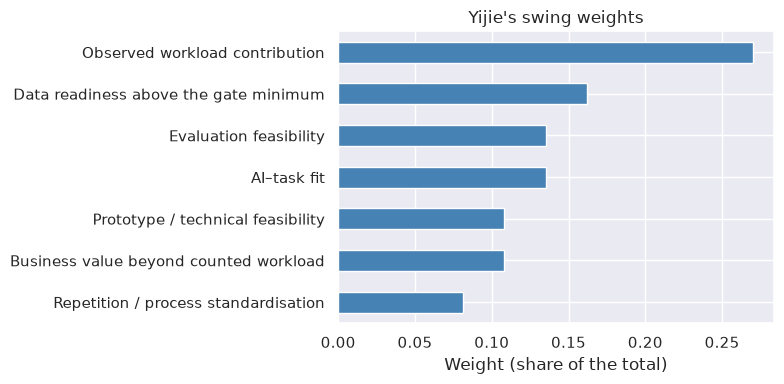

In [14]:
ax = weights.sort_values("weight").plot(kind="barh", x="label", y="weight", legend=False, color="steelblue", figsize=(8, 4))
ax.set_xlabel("Weight (share of the total)")
ax.set_ylabel("")
ax.set_title("Yijie's swing weights")
plt.tight_layout()
plt.show()

**Why these swings.**

| Criterion | Swing | Weight | Reason for the swing |
|---|---:|---:|---|
| Observed workload contribution | 100 | 27.0% | Reducing the buyer's workload is the research objective, so moving from under 5% to over 15% of the time matters most. |
| Data readiness above the gate minimum | 60 | 16.2% | Decides how good the prototype and its test can be; gate 2 already sets the minimum. |
| AI–task fit | 50 | 13.5% | The company expects AI in the focal solution; gate 6 already removes tasks a simple rule could do. |
| Evaluation feasibility | 50 | 13.5% | Needed to answer SQ5; gate 3 already sets the minimum. |
| Prototype / technical feasibility | 40 | 10.8% | Gate 5 already removes what does not fit the BEP. |
| Business value beyond counted workload | 40 | 10.8% | Secondary to the workload objective. |
| Repetition / process standardisation | 30 | 8.1% | Frequency is already partly counted under workload. |

Criteria that only score what lies above a gate get a lower swing, because the gate has already removed the worst cases. The workload figures were known before the weights were set; the weights were recorded before any scoring. Knowledge of the workload figures is a limitation; recording weights before scoring preserves the order of the provisional exercise. The 9 October anchor clarifications have not prompted an invented re-elicitation.

## 6. Scores

The original scenario assigned each candidate a 1–5 score using the original anchors, with:

- the **evidence** behind it, from the [evidence matrix](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Candidate_Evidence_Matrix_2026-10-07.md), the analysis notebook, the draft causes (IDs such as PC-5) and the AI function comparison;
- a **low and a high value** for the uncertainty in that evidence, used in part 8.

Order and confirmation checking is scored on the boundary of the scoring brief (decision 5), widened on 7 October: checking supplier quotations before ordering and confirmations after ordering against the PO, for price, delivery date, quantity and missing or extra lines. The scenario uses 98 minutes of broad checking work; that is not a measured total for the narrower proposed intervention. The scores were set for the earlier price boundary, under the name purchase-price control, and are kept as recorded. The [boundary and score review](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Candidate_Evidence_Matrix_2026-10-07.md#review-of-the-broadened-order-checking-scores) identifies what carries over and the unresolved evidence for each criterion. Final rescoring needs the agreed boundary/anchors and actual inputs; it cannot be completed by relabelling the old numbers. Maximalisatie and request intake are scored on their narrowed outputs from part 3, including their workload. A low data-readiness score cannot absorb a failed gate: if the test account lacks the data, gates 2 and 3 reopen.

The 98 minutes include 4 minutes attaching a confirmation; the observer clarification supports 94 minutes related to price/date. Quantity and missing/extra-line checking do not have separately measured historical durations. The broadened boundary does not inherit validated data availability, reference answers or buyer acceptance from the price-focused scenario.

**Source-review boundary uncertainty, 9 October.** See the [targeted review log](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Targeted_Label_Review_2026-10-09.csv). Two K18 episodes on 18 September, source rows 3 (5 minutes, Kayne price enquiry) and 73 (6 minutes, the €410 price investigation), do not establish whether a quotation, confirmation, pre-order or invoice comparison was involved. Their 11 minutes remain in broad checking; eligibility for the narrower quotation/confirmation artifact is unresolved. The 98/94/28-minute distinctions therefore describe broad recorded evidence, not validated addressable or avoidable workload. A mixed MAX/PO interval on 31 August source row 52 also warrants label review against the comparable mixed interval on 18 September row 52. No duration has been split and no labels or numerical scores changed from these uncertainties.

In [15]:
# Scores for Order and confirmation checking: criterion, score, low, high, evidence
score_rows = []

candidate = 'Order and confirmation checking'
score_rows += [
    (candidate, 'workload', 5, 4, 5,
     'All order checks: 98 of 560 minutes (17.5%) on all five days, 19 case-days; recorded'
     ' difficulties on 31 Aug, 1 and 18 Sep (missing delivery date, blocked check, '
     'unexplained mismatch, price differences) [notebook parts 9–10]; 94 of the 98 minutes'
     ' are checks of price and/or delivery date (observer clarification, 7 October). Low '
     'end: the source-to-label desk review retains owner/boundary questions; full blind recoding is optional.'),
    (candidate, 'business_value', 3, 3, 4,
     'Dennis reported Sales losses from outdated purchase prices (15 September); buyers '
     'lack time for updates (2 October), repeated at the 8 October meeting. Qualitative '
     'business relevance is supported. Financial impact and achievable benefit remain '
     'unquantified; Johan\'s confirmation with examples or figures is still to come.'),
    (candidate, 'ai_fit', 4, 3, 4,
     'Reading prices and lines from paper, PDF, website and email documents and matching '
     'them to PO lines is the core of the task; precedent Tater et al. (2022) [AI table '
     'rows 5–7]. Low end: if documents are structured, only matching needs AI.'),
    (candidate, 'data_readiness', 3, 2, 4,
     'PO lines are standard Exact data; confirmations and approved prices are expected but'
     ' not yet seen in the test account [checks PC1–PC4]. If they are missing, gates 2–3 '
     'reopen; this score does not absorb that.'),
    (candidate, 'repetition', 3, 3, 4,
     'Every day, 19 case-days; the task is stable (compare price and date per line) but '
     'inputs vary in format and size, 1 to 29 lines [notebook part 5].'),
    (candidate, 'prototype', 3, 3, 4,
     'Proposed route: exports and documents with manual steps, without integration; '
     'not yet demonstrated [check G6].'),
    (candidate, 'evaluation', 4, 3, 5,
     "Proposed reference per line (a buyer-validated approved price) and Zhongxin's fallback of test "
     'workloads from past orders; the observed time per line is imprecise, so the time '
     'baseline is weak [notebook part 5].'),
]

In [16]:
# Scores for Article / supplier data: criterion, score, low, high, evidence
candidate = 'Article / supplier data'
score_rows += [
    (candidate, 'workload', 3, 3, 3,
     '39 minutes (7.0%) on four days, 5 case-days; one case blocked for a day by missing '
     'data [notebook part 9].'),
    (candidate, 'business_value', 1, 1, 2,
     'No effect named beyond buyer time.'),
    (candidate, 'ai_fit', 4, 3, 4,
     'Extracting item fields from supplier documents in different layouts is the core of '
     'the task; precedent Šimsa et al. (2023), a benchmark [AI table row 4].'),
    (candidate, 'data_readiness', 3, 2, 4,
     'Article records exist; whether their source documents are linked is not yet known '
     '[checks AR1, AR2].'),
    (candidate, 'repetition', 2, 2, 3,
     'Four of five days, 5 case-days; item data differ per article.'),
    (candidate, 'prototype', 3, 2, 4,
     'Can run on exported article records and supplier documents [checks G6, AR2].'),
    (candidate, 'evaluation', 3, 2, 4,
     'Existing article records can be the reference; few cases per week [check AR3].'),
]

In [17]:
# Scores for Maximalisatie: criterion, score, low, high, evidence
candidate = 'Maximalisatie'
score_rows += [
    (candidate, 'workload', 3, 3, 3,
     '43 minutes (7.7%) on all five days, 16 case-days [notebook part 9]. The list '
     'supports finding demand to combine; the decision time itself cannot be separated.'),
    (candidate, 'business_value', 3, 2, 3,
     'One effect named: each PO costs time and money (Dennis via Yijie, 2 October); '
     'example of 4 lines added to a 12-line PO (31 Aug OBS-15).'),
    (candidate, 'ai_fit', 2, 1, 3,
     'The narrowed version is close to a rule (same supplier, open PO); AI only for '
     'matching demand descriptions [AI table row 8].'),
    (candidate, 'data_readiness', 2, 1, 3,
     'Past advice and stock states are unlikely to be stored; open POs probably are '
     '[checks MX1–MX3].'),
    (candidate, 'repetition', 3, 3, 3,
     'Every day, 16 case-days; inputs vary with stock, urgency and order value '
     '[opportunity profile A].'),
    (candidate, 'prototype', 2, 1, 3,
     'Needs open-PO and demand data, possibly Orbis [check MX4].'),
    (candidate, 'evaluation', 3, 2, 3,
     'The narrowed list can be checked against the lines later added to the same open PO '
     '[check MX3]; how many such cases the account holds is not yet known.'),
]

In [18]:
# Scores for Request intake & validation: criterion, score, low, high, evidence
candidate = 'Request intake & validation'
score_rows += [
    (candidate, 'workload', 3, 3, 3,
     'Narrowed to finding old POs and drawings (K10, K11): 45 of 560 minutes (8.0%, '
     'including 4 mixed minutes) in 8 records on three days [labels file].'),
    (candidate, 'business_value', 2, 1, 3,
     'Incomplete drawing sets from Engineering delay orders (RI-10); no business effect '
     'beyond buyer time is named.'),
    (candidate, 'ai_fit', 3, 2, 4,
     'Finding the right old PO or drawing from free-text item descriptions needs AI for '
     'the search; weak precedent (Lombardi et al., 2025, other drawing domain) [AI table '
     'row 1].'),
    (candidate, 'data_readiness', 2, 1, 3,
     'Old POs are in Exact; where drawings are kept and how they link to items is unknown '
     '[checks RI2, RI3].'),
    (candidate, 'repetition', 2, 1, 2,
     'Three of five days, 8 records in a few case-days; each search differs.'),
    (candidate, 'prototype', 2, 1, 3,
     "Depends on access to the drawing archive and on searching Exact's item history "
     '[check RI2].'),
    (candidate, 'evaluation', 3, 2, 3,
     'The old PO or drawing that was actually used is the reference; few cases were '
     'observed (two drawing cases, two searches).'),
]

In [19]:
# Scores of the candidates that passed Stage A, in the order of the weights
scores = pd.DataFrame(score_rows, columns=["candidate", "criterion", "score", "low", "high", "evidence"])
scored = scores.loc[scores["candidate"].isin(stage_a.index[stage_a["scored_in_stage_b"]])]
score_table = scored.pivot(index="candidate", columns="criterion", values="score")[weights.index]
score_table

criterion,workload,business_value,ai_fit,data_readiness,repetition,prototype,evaluation
candidate,,,,,,,
Article / supplier data,3,1,4,3,2,3,3
Maximalisatie,3,3,2,2,3,2,3
Order and confirmation checking,5,3,4,3,3,3,4
Request intake & validation,3,2,3,2,2,2,3


**Evidence behind the retained 7 October scores.** This is an audit of that provisional scenario, not a new scoring against the broadened boundary.

| Criterion | Score (range) | Anchor reached | Why not higher | Why the range |
|---|---|---|---|---|
| Observed workload | 5 (4–5) | Over 15% with recorded burden on several days: 98 of 560 minutes (17.5%) on all five days, 94 of them checks of price and/or delivery date, with recorded difficulties on 31 August, 1 and 18 September | It is the top score | Low 4: the desk review retains unresolved coding-owner and boundary questions. A price-only boundary (28 minutes, 5.0%) would give 3; part 8 tests that separately |
| Business value | 3 (3–4), retained | Dennis reported Sales losses from outdated purchase prices on 15 September; the 2 October account reports insufficient time for regular updates | 5 needs the company supervisor to confirm the effect with examples or figures (condition 4); the path from a flag to an achieved benefit is not established | High 4 if Johan gives examples |
| AI–task fit | 4 (3–4) | Close to 5: reading prices and lines from paper, PDF, website and email and matching them to PO lines is the core of the task | The precedent (Tater et al., 2022) concerns invoices, not confirmations, and is not yet read in full | Low 3 if the documents turn out to be structured, so that only the matching needs AI |
| Data readiness | 3 (2–4) | Enough past cases expected with moderate cleaning: PO lines are standard Exact data | Confirmations and approved prices are expected but not yet seen in the test account (checks PC1–PC4) | Low 2 if few are stored; high 4 if they can be exported with a traceable price |
| Repetition | 3 (3–4) | Every day, but inputs vary: 19 case-days on all five days, 1 to 29 lines, four document formats | 5 needs stable inputs | High 4 if the session with Arno shows a stable routine |
| Prototype feasibility | 3 (3–4) | Can be built on exports and documents with manual steps, no integration | The export route is not yet tested (check G6) | High 4 if exports work without manual steps |
| Evaluation feasibility | 4 (3–5) | Close to 5: a buyer-validated approved price per line is a proposed reference answer, and test workloads from past orders are possible | The time per checked line is imprecise (part 5 of the analysis notebook), and the number of past cases is unknown | Low 3 if few cases exist; high 5 if many cases with a traceable price |

## 7. Totals

The total is the sum of weight × score ÷ 5, multiplied by 100. A 5 on every criterion gives 100; a 1 on every criterion gives 20. In the code, `@` multiplies each score by its weight and adds the results.

First the calculation for order and confirmation checking, criterion by criterion.

In [20]:
# Worked example: the points order and confirmation checking gets on each criterion
example = pd.DataFrame({
    "weight": weights["weight"],
    "score": score_table.loc["Order and confirmation checking"],
})
example["points"] = example["weight"] * example["score"] / 5 * 100
print("Total:", round(example["points"].sum(), 1))
example.round(3)

Total: 76.2


,weight,score,points
criterion,,,
workload,0.270,5,27.027
business_value,0.108,3,6.486
ai_fit,0.135,4,10.811
data_readiness,0.162,3,9.730
repetition,0.081,3,4.865
prototype,0.108,3,6.486
evaluation,0.135,4,10.811


In [21]:
# Weighted totals of all candidates, from 0 to 100
totals = (score_table @ weights["weight"] / 5 * 100).sort_values(ascending=False).to_frame("total")
totals["lead_over_next"] = totals["total"] - totals["total"].shift(-1)
totals.round(1)

,total,lead_over_next
candidate,,
Order and confirmation checking,76.2,19.5
Article / supplier data,56.8,4.9
Maximalisatie,51.9,1.1
Request intake & validation,50.8,NaN


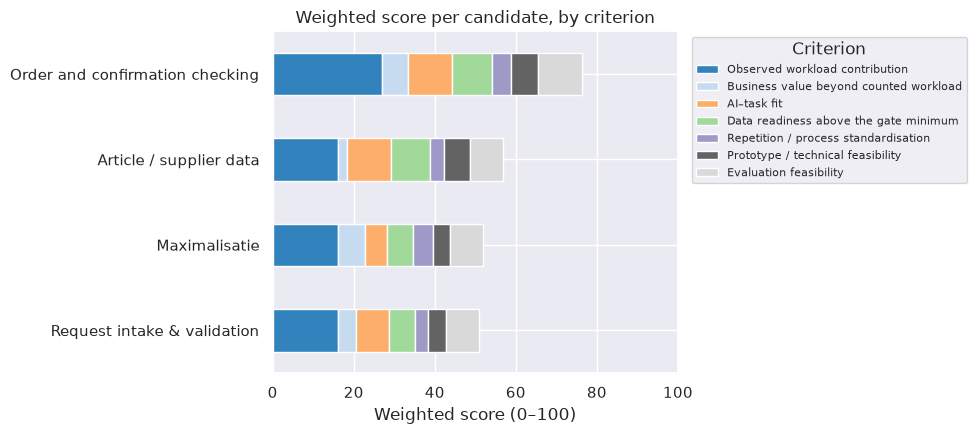

In [22]:
# Contribution of each criterion to each total
contributions = score_table.mul(weights["weight"], axis=1) / 5 * 100
contributions = contributions.loc[totals.index[::-1]]
contributions.columns = weights.loc[contributions.columns, "label"]

ax = contributions.plot(kind="barh", stacked=True, figsize=(10, 4.5), colormap="tab20c")
ax.set_xlabel("Weighted score (0–100)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Weighted score per candidate, by criterion")
ax.legend(title="Criterion", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Reading.** In the retained 7 October scenario, order and confirmation checking scores highest or joint highest on every criterion, so its lead does not depend on one weight. Its largest advantage is workload: the order checks take 17.5% of the recorded time, against 7–8% for the others in the form they are scored. It also leads on evaluation feasibility (the proposal assumes that valid price references and suitable cases can be established; this remains unverified) and equals the best on business value, AI–task fit, data readiness and prototype feasibility. Article data has a good AI fit but no business effect named. Maximalisatie's narrowed list is close to a rule. Request intake's narrowed retrieval is small and occurred on only three days.

## 8. Sensitivity

The methodology (§5.3) asks for at least (a) equal weights, (b) each weight changed by ±20% and (c) disputed scores changed by ±1; if the leader changes, the ranking is reported as unstable or a shortlist is kept. This part runs those checks and four more that use the low and high value of every score.

| Check | Question |
|---|---|
| 1. Equal weights | Does the leader depend on the weights at all? |
| 2. Each weight ±20% | Does one weight decide the result? |
| 3. Each score ±1 | Does one score decide the result? |
| 4. Price-only boundary | What if the workload counted only the 28 minutes whose note names price? |
| 5. Combined changes | How many one-point changes, within the ranges, would put another candidate first? |
| 6. Stress test | Who leads with order and confirmation checking at all its low values and the others at all their high values? |
| 7. Random draws | How often does order and confirmation checking lead when every score is drawn at random within its range? An illustration, not a probability. |

In [23]:
# Low and high value of every score, and the leading candidate
low = scored.pivot(index="candidate", columns="criterion", values="low")[weights.index]
high = scored.pivot(index="candidate", columns="criterion", values="high")[weights.index]
leader = totals.index[0]
print("Leader:", leader)

Leader: Order and confirmation checking


In [24]:
# 1. Equal weights
equal = pd.Series(1 / len(weights), index=weights.index)
equal_totals = (score_table @ equal / 5 * 100).sort_values(ascending=False)
equal_totals.round(1)

candidate
Order and confirmation checking    71.4
Article / supplier data            54.3
Maximalisatie                      51.4
Request intake & validation        48.6
dtype: float64

In [25]:
# 2. Each weight 20% higher or lower, the others rescaled so the weights add up to 100%
rows = []
for criterion in weights.index:
    for change in [0.8, 1.2]:
        w = weights["weight"].copy()
        w[criterion] *= change
        w = w / w.sum()
        t = (score_table @ w / 5 * 100).sort_values(ascending=False)
        rows.append([criterion, f"{change - 1:+.0%}", t.index[0], t.iloc[0] - t.iloc[1]])
weight_checks = pd.DataFrame(rows, columns=["criterion", "weight_change", "leader", "lead_over_next"])
print("Leaders across the 14 weight changes:", weight_checks["leader"].value_counts().to_dict())
weight_checks.round(1)

Leaders across the 14 weight changes: {'Order and confirmation checking': 14}


,criterion,weight_change,leader,lead_over_next
0,workload,-20%,Order and confirmation checking,18.3
1,workload,+20%,Order and confirmation checking,20.5
2,business_value,-20%,Order and confirmation checking,19.0
3,business_value,+20%,Order and confirmation checking,19.9
4,ai_fit,-20%,Order and confirmation checking,20.0
5,ai_fit,+20%,Order and confirmation checking,18.9
6,data_readiness,-20%,Order and confirmation checking,20.1
7,data_readiness,+20%,Order and confirmation checking,18.8
8,repetition,-20%,Order and confirmation checking,19.5
9,repetition,+20%,Order and confirmation checking,19.5


In [26]:
# 3. Each score one point higher or lower, one at a time
rows = []
for candidate in score_table.index:
    for criterion in score_table.columns:
        for change in [-1, 1]:
            s = score_table.copy()
            s.loc[candidate, criterion] = min(5, max(1, s.loc[candidate, criterion] + change))
            t = (s @ weights["weight"] / 5 * 100).sort_values(ascending=False)
            rows.append([candidate, criterion, change, t.index[0], t.iloc[0] - t.iloc[1]])
score_checks = pd.DataFrame(rows, columns=["candidate", "criterion", "change", "leader", "lead_over_next"])
print("Leaders across the", len(score_checks), "score changes:", score_checks["leader"].value_counts().to_dict())
print("Smallest lead:", round(score_checks["lead_over_next"].min(), 1), "points")

Leaders across the 56 score changes: {'Order and confirmation checking': 56}
Smallest lead: 14.1 points


In [27]:
# 4. Price-only boundary for order and confirmation checking: 28 minutes (5.0%) gives workload score 3
price_only = score_table.copy()
price_only.loc["Order and confirmation checking", "workload"] = 3
price_only_totals = (price_only @ weights["weight"] / 5 * 100).sort_values(ascending=False)
price_only_totals.round(1)

candidate
Order and confirmation checking    65.4
Article / supplier data            56.8
Maximalisatie                      51.9
Request intake & validation        50.8
dtype: float64

In [28]:
# 5. Fewest one-point changes within the ranges that put another candidate ahead.
# Each change moves the gap by its weight x 20 points, so taking the largest changes first gives the fewest.
rows = []
for challenger in score_table.index.drop(leader):
    steps = []
    for c in score_table.columns:
        points = weights.loc[c, "weight"] * 20
        steps += [[f"{leader}: {c} -1", points]] * int(score_table.loc[leader, c] - low.loc[leader, c])
        steps += [[f"{challenger}: {c} +1", points]] * int(high.loc[challenger, c] - score_table.loc[challenger, c])
    steps = pd.DataFrame(steps, columns=["change", "points"]).sort_values("points", ascending=False, kind="stable")
    steps["gap_closed"] = steps["points"].cumsum()
    gap = totals.loc[leader, "total"] - totals.loc[challenger, "total"]
    if steps["gap_closed"].max() > gap:
        n = int((steps["gap_closed"] <= gap).sum()) + 1
        rows.append([challenger, gap, len(steps), n, "; ".join(steps["change"].head(n))])
    else:
        rows.append([challenger, gap, len(steps), np.nan, "not possible within the ranges"])
combined = pd.DataFrame(rows, columns=["challenger", "gap_points", "changes_available", "fewest_changes_needed", "those_changes"])
with pd.option_context("display.max_colwidth", 300):
    display(combined.round(1))

,challenger,gap_points,changes_available,fewest_changes_needed,those_changes
0,Article / supplier data,19.5,9,6.0,Order and confirmation checking: workload -1; Order and confirmation checking: data_readiness -1; Article / supplier data: data_readiness +1; Order and confirmation checking: ai_fit -1; Order and confirmation checking: evaluation -1; Article / supplier data: evaluation +1
1,Maximalisatie,24.3,7,NaN,not possible within the ranges
2,Request intake & validation,25.4,8,NaN,not possible within the ranges


In [29]:
# 6. Stress test: the leader at its low values, every other candidate at its high values
stress = high.copy()
stress.loc[leader] = low.loc[leader]
stress_totals = (stress @ weights["weight"] / 5 * 100).sort_values(ascending=False)
stress_totals.round(1)

candidate
Article / supplier data            68.6
Order and confirmation checking    62.2
Request intake & validation        61.1
Maximalisatie                      60.0
dtype: float64

In [30]:
# 7. Random draws: each score drawn independently and uniformly from its low-high range
rng = np.random.default_rng(20261007)
draws = 10000
wins = pd.Series(0, index=score_table.index)
tied_draws = 0
for _ in range(draws):
    s = pd.DataFrame(rng.integers(low.to_numpy(), high.to_numpy() + 1), index=low.index, columns=low.columns)
    # Whole-number swing totals keep the ranking exact, so ties are found reliably
    draw_totals = s @ weights["swing"]
    leaders = draw_totals.index[draw_totals.eq(draw_totals.max())]
    if len(leaders) == 1:
        wins[leaders[0]] += 1
    else:
        tied_draws += 1

print("Strict wins by a candidate other than the main leader:", wins.sum() - wins[leader], "of", draws)
print("Draws tied for first place:", tied_draws, "of", draws)
pd.DataFrame({"strict_wins": wins, "share_of_all_draws_strictly_won_pct": wins / draws * 100}).sort_values("strict_wins", ascending=False).round(2)

Strict wins by a candidate other than the main leader: 8 of 10000
Draws tied for first place: 8 of 10000


,strict_wins,share_of_all_draws_strictly_won_pct
candidate,,
Order and confirmation checking,9984,99.84
Article / supplier data,8,0.08
Maximalisatie,0,0.00
Request intake & validation,0,0.00


In [31]:
# Summary of the checks
summary = pd.DataFrame([
    ["Swing weights (main result)", totals.index[0], totals["total"].iloc[0] - totals["total"].iloc[1]],
    ["1. Equal weights", equal_totals.index[0], equal_totals.iloc[0] - equal_totals.iloc[1]],
    ["2. Each weight ±20% (14 cases)", weight_checks["leader"].mode()[0] + f" in {(weight_checks['leader'] == leader).sum()} of 14", weight_checks["lead_over_next"].min()],
    ["3. Each score ±1 (" + str(len(score_checks)) + " cases)", score_checks["leader"].mode()[0] + f" in {(score_checks['leader'] == leader).sum()} of {len(score_checks)}", score_checks["lead_over_next"].min()],
    ["4. Price-only boundary", price_only_totals.index[0], price_only_totals.iloc[0] - price_only_totals.iloc[1]],
    ["5. Combined changes", leader + f" until {int(combined['fewest_changes_needed'].min())} one-point changes", np.nan],
    ["6. Stress test", stress_totals.index[0], stress_totals.iloc[0] - stress_totals.iloc[1]],
    ["7. Random draws (illustration)", wins.idxmax() + f": {wins.max()} strict wins; {tied_draws} draws tied for first", np.nan],
], columns=["check", "leader", "smallest_lead_points"])

with pd.option_context("display.max_colwidth", 80):
    display(summary.round(1))

,check,leader,smallest_lead_points
0,Swing weights (main result),Order and confirmation checking,19.5
1,1. Equal weights,Order and confirmation checking,17.1
2,2. Each weight ±20% (14 cases),Order and confirmation checking in 14 of 14,18.3
3,3. Each score ±1 (56 cases),Order and confirmation checking in 56 of 56,14.1
4,4. Price-only boundary,Order and confirmation checking,8.6
5,5. Combined changes,Order and confirmation checking until 6 one-point changes,NaN
6,6. Stress test,Article / supplier data,6.5
7,7. Random draws (illustration),Order and confirmation checking: 9984 strict wins; 8 draws tied for first,NaN


**Reading.** Order and confirmation checking stays first in every check that changes one thing at a time: with equal weights (lead 17.1 points), with each weight ±20% (smallest lead 18.3), with each score ±1 (smallest lead 14.1) and with the price-only boundary (lead 8.6). The ranking is stable under these single-change checks for the recorded assumptions. This does not close open gates or validate the broader boundary.

Combinations of plausible changes can reverse it. Six one-point changes within the recorded ranges put article data ahead: order and confirmation checking one point lower on workload, data readiness, AI–task fit and evaluation, and article data one point higher on data readiness and evaluation. Maximalisatie and request intake cannot overtake within their ranges. In the stress test, with every score at its worst for order and confirmation checking and its best for the others, article data leads (68.6 against 62.2). Among the 10,000 random draws, order and confirmation checking wins strictly in 9,984 and article data in 8; the two tie for first in another 8. These counts follow from the ranges and the independent, uniform sampling, so they illustrate the ranges rather than give a probability.

Four of the six reversing changes are the focal case's own data readiness, evaluation, workload and AI fit. The first two depend on the test account, so checks PC1–PC4 come first; if they fail, the question is no longer the score but gates 2 and 3.

## 9. The focal case

**Order and confirmation checking is the provisional focal case.** Until 7 October it was called purchase-price control.

**Task boundary** (scoring brief, decision 5, widened on 7 October): checking supplier quotations before ordering and order confirmations after ordering against the PO, for price, delivery date, quantity and missing or extra lines. Related broad checking workload: 98 of 560 minutes (17.5%) on all five days. This is not a measured eligible-task total; 11 K18 minutes have an unresolved document/process boundary (part 6). By the observer's clarification of 7 October, 94 of them are checks of price and/or delivery date; 28 are in records whose note names price.

**Proposed support, to be designed in Improve:** read the price, quantity and delivery date per line from the quotation or confirmation (scan, PDF, email or website), match the lines to the PO, and flag differences and missing or extra lines for the buyer. Within a proposed standard / review / manual frame, the interface distinguishes unflagged lines, flagged lines and unreadable or unmatched material, with human checking and manual fallback. An unflagged line is not proof of correctness and does not authorize release. Nothing changes in Exact, no PO is created or sent, and no changed commercial term is accepted automatically. Yijie reported buyer opposition to automatic PO creation and email sending on 8 October; acceptance of this bounded review aid remains open.

**Conditions before Improve.** Gate 1 is settled: Johan's permission covers the test-account data and processing its documents with an external AI service (checks G1–G2, confirmed by Yijie on 7 October). Four conditions remain; each settles a provisional gate or a step the charter requires:

| Required input | What to establish | Consequence |
|---|---|---|
| 1. Relevant test-account and reference checks | Start with PC1–PC4; inspect paired PO/supplier-document versions and each retained field. Establish document transcription, discrepancy labels and the accepted business action separately, then confirm export and buyer-testing feasibility. | Gates 2, 3 and 5 remain open. A permitted, representative alternative or a narrower boundary is needed if the data/reference fails; a lower score cannot absorb that failure. |
| 2. Arno's acceptance of the bounded support | Ask about reading, matching and flagging with visible sources, correction and manual fallback. Record separately any proposal to draft, change or send. | Gate 4. The reported objection to automatic creation and sending does not establish acceptance or rejection of a review aid. |
| 3. Boundary, criteria, scores and weights reviewed with Zhongxin | Review the wider scope, the anchors, the criterion-by-criterion gaps and the weighting procedure; record the final set and rescore before final selection. | Supervisor alignment and a justified final comparison. Independent swings are the existing proposed procedure, not a confirmed 8 October requirement. |
| 4. Johan's business value | Examples or figures of the effect, starting from Dennis's explanation that outdated purchase prices led to loss-making sales | The business-value score; permission to use the data does not establish business value |

**Business-value evidence so far.** Dennis reported Sales selling at a loss because prices relied on outdated purchase data ([15 September notes](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/meetings/Internship_notes_2026-09-15.md#prices-and-updates)); the [2 October account](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/measurement/Arno_Follow_Up_Session_Guide_2026-10-02.md#what-yijie-reported-on-2-october) adds that regular updates are missed because of limited time. Yijie repeated this example on [8 October](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/meetings/Academic_Supervisor_Meeting_Notes_2026-10-08.md#buyer-acceptance-and-the-business-value-example). This supports a business-value score of 3. Financial impact and achievable benefit are unquantified, and a flag only prevents such losses if the checking result reaches price maintenance. Johan's confirmation (condition 4) is needed for a higher score.

The [9 October source-to-label review](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Targeted_Label_Review_2026-10-09.csv) checks relevant workload evidence without changing labels or times. Resolve its coding-owner/boundary questions and carry any justified correction into this comparison. Completing every row of the Stage A worksheet, or another general observation round, is not a separate condition.

**The other candidates.**

- **Article / supplier data** is the runner-up (56.8) and the first fallback if order and confirmation checking fails its gates; its own gates 2–3 depend on checks AR1–AR2.
- **Maximalisatie** and **request intake & validation** stay as further opportunities in their narrowed form.
- **PO supplier communication** becomes a quick-win recommendation with ordinary automation, outside the AI artifact.
- **Standard / review / manual** is the design frame of the focal case.

**Limitations.** The retained totals use the 7 October scores, not a rescore of the broader boundary. One assessor so far; Zhongxin's review follows. The evidence comes from five partial sessions of one buyer, and the source-to-label desk review retains coding-owner/boundary questions; overall inter-coder reliability is not established. An observed case without a recorded problem is not proof of a routine case. The workload figures were known before the weights were set; the weights were recorded before any scoring. The verdicts and scores were drafted from the evidence matrix with AI assistance and reviewed by Yijie.

**What comes next.** The focal case answers SQ4. The following work supports SQ2 and SQ5, in the order set out in part 11 of the analysis notebook:

1. **Design the AI support (SQ2, Improve phase).** Which inputs it reads, what it compares and flags, what the buyer decides, and which controls keep its errors detectable and reversible. Condition 2 above (Arno's acceptance) is the first input.
2. **Quantify the workload reduction (SQ5).** Before building, freeze the evaluation design ([methodology §6.1](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Phase_1_Current_Methodology.md#61-workload-endpoint-and-quality-guardrail)): eligible cases, reference answers, the workload measure, the smallest worthwhile reduction and the quality guardrail. Then compare the manual and AI-supported checks on agreed comparable cases, with learning/order effects addressed in the frozen design. The observed time per line is too imprecise to serve as the baseline (part 5 of the analysis notebook), so the manual checks are timed for the evaluation itself.

## Sources

Belton, V., & Stewart, T. J. (2002). *Multiple criteria decision analysis: An integrated approach*. Kluwer Academic Publishers. https://doi.org/10.1007/978-1-4615-1495-4

Department for Communities and Local Government. (2009). *Multi-criteria analysis: A manual*. https://www.gov.uk/government/publications/multi-criteria-analysis-manual-for-making-government-policy

Goodhue, D. L., & Thompson, R. L. (1995). Task-technology fit and individual performance. *MIS Quarterly, 19*(2), 213–236. https://doi.org/10.2307/249689

Parasuraman, R., Sheridan, T. B., & Wickens, C. D. (2000). A model for types and levels of human interaction with automation. *IEEE Transactions on Systems, Man, and Cybernetics – Part A, 30*(3), 286–297. https://doi.org/10.1109/3468.844354

Peffers, K., Tuunanen, T., Rothenberger, M. A., & Chatterjee, S. (2007). A design science research methodology for information systems research. *Journal of Management Information Systems, 24*(3), 45–77.

Tater, T., et al. (2022). AI driven accounts payable transformation. *Proceedings of the AAAI Conference on Artificial Intelligence, 36*(11), 12405–12413. https://doi.org/10.1609/aaai.v36i11.21506

Triantaphyllou, E., & Sánchez, A. (1997). A sensitivity analysis approach for some deterministic multi-criteria decision-making methods. *Decision Sciences, 28*(1), 151–194. https://doi.org/10.1111/j.1540-5915.1997.tb01306.x

The reading status of each source is kept in the [literature register](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/literature/README.md). Several have not yet been read in full; read the relevant parts before citing them in the thesis.